In [26]:
pip install pycwt


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime
import statsmodels.api as sm
from statsmodels.tsa.stattools import ccf
import scipy.stats 
from scipy.stats import pearsonr, ttest_ind_from_stats


from pycwt import wavelet, helpers
from pycwt.wavelet import Morlet


plt.style.use('seaborn-v0_8-darkgrid')
sns.set_context("notebook")


ROOT_DIR = './'
FINANCE_DATA_DIR = os.path.join(ROOT_DIR, 'data', 'finance')
SENTIMENT_DATA_DIR = os.path.join(ROOT_DIR, 'data', 'sentiment')

STOCK_TICKERS = ['AAPL', 'MSFT', 'TSLA', 'AMZN', 'GOOG']
BTC_TICKER = 'BTC'  

SENTIMENT_STOCK_FILE = 'stock_with_vader_normalized.csv'
SENTIMENT_BTC_FILE = 'bitcoin_with_vader_normalized.csv'

dfs_finance_raw = {}
dfs_sentiment_raw = {}


def test_wavelet_analysis():

    t = np.linspace(0, 1, 200)
    signal = np.sin(2 * np.pi * 10 * t) + np.random.randn(200) * 0.5

    dt = t[1] - t[0]
    dj = 0.25
    s0 = 2 * dt
    J = 7 / dj
    mother = Morlet(6)

    wave, scales, freqs, coi, fft, fftfreqs = wavelet.cwt(signal, dt, dj, s0, J, mother)

    plt.contourf(t, np.log2(freqs), np.abs(wave), extend='both')
    plt.ylabel('log2(Frequency)')
    plt.xlabel('Time (s)')
    plt.title('Wavelet Power Spectrum')
    plt.show()




In [ ]:
def load_finance_data(ticker, data_dir):
    """Loads financial data for a given ticker."""
    file_path = os.path.join(data_dir, f"{ticker}_data.csv")
    print(f"Attempting to load financial data: {file_path}")
    try:

        df = pd.read_csv(file_path, parse_dates=['Date'], date_format='%m/%d/%Y')
        df = df.set_index('Date')
        df = df.sort_index()
        print(f"Loaded financial data for {ticker}: {file_path}")
        return df
    except FileNotFoundError:
        print(f"Error: File not found for {ticker} at {file_path}")
        return None
    except Exception as e:
        print(f"Error loading financial data for {ticker} at {file_path}: {e}")
        return None

def load_sentiment_data(file_name, data_dir):
    """Loads sentiment data with robust date parsing."""
    file_path = os.path.join(data_dir, file_name)
    print(f"Attempting to load sentiment data: {file_path}")
    try:

        df = pd.read_csv(file_path)
        print(f"Successfully read CSV: {file_path}, Shape: {df.shape}")

        if 'datetime' not in df.columns:
             print(f"Error: 'datetime' column not found in {file_path}")
             return None

        original_count = len(df)
        print(f"Parsing 'datetime' column for {original_count} entries...")

        df['datetime_parsed'] = pd.to_datetime(df['datetime'], errors='coerce', utc=True) 


        nat_count = df['datetime_parsed'].isna().sum()
        if nat_count > 0:
            print(f"Warning: Could not parse {nat_count} out of {original_count} datetime strings in {file_name}. These rows will be dropped.")
            df = df.dropna(subset=['datetime_parsed'])
            print(f"Remaining rows after dropping NaT dates: {len(df)}")

        if df.empty:
             print(f"Error: No valid datetime entries found after parsing in {file_name}")
             return None

        df['datetime'] = df['datetime_parsed'].dt.tz_localize(None)
        df = df.drop(columns=['datetime_parsed']) 

        df = df.sort_values('datetime') 


        keep_cols = ['datetime', 'ticker', 'compound'] if 'ticker' in df.columns else ['datetime', 'compound']
        keep_cols = [col for col in keep_cols if col in df.columns] 

        print(f"Finished processing sentiment data: {file_path}, Final shape: {df[keep_cols].shape}")

        return df[keep_cols].copy()

    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
        return None
    except pd.errors.EmptyDataError:
        print(f"Error: File is empty at {file_path}")
        return None
    except MemoryError:
        print(f"Error: MemoryError loading {file_path}. The file might be too large to load into memory directly.")
        print("Consider preprocessing the file or using chunking/dask for analysis.")
        return None
    except Exception as e:
         print(f"Error loading or processing sentiment data {file_path}: {e}")
         import traceback
         traceback.print_exc()
         return None

print("--- Loading Financial Data ---")
all_tickers = STOCK_TICKERS + [BTC_TICKER]
for ticker in all_tickers:
    dfs_finance_raw[ticker] = load_finance_data(ticker, FINANCE_DATA_DIR)

print("\n--- Loading Sentiment Data ---")

dfs_sentiment_raw['stocks'] = load_sentiment_data(SENTIMENT_STOCK_FILE, SENTIMENT_DATA_DIR)

dfs_sentiment_raw['btc'] = load_sentiment_data(SENTIMENT_BTC_FILE, SENTIMENT_DATA_DIR)


if dfs_sentiment_raw.get('stocks') is not None:
    print(f"\nFiltering stock sentiment for tickers: {STOCK_TICKERS}")
    original_stock_rows = len(dfs_sentiment_raw['stocks'])
    dfs_sentiment_raw['stocks'] = dfs_sentiment_raw['stocks'][dfs_sentiment_raw['stocks']['ticker'].isin(STOCK_TICKERS)].copy() # Use .copy()
    print(f"Original stock sentiment entries: {original_stock_rows}")
    print(f"Filtered stock sentiment entries: {len(dfs_sentiment_raw['stocks'])}")
else:
    print("Skipping stock sentiment filtering as data failed to load.")


required_data_loaded = True
print("\n--- Data Loading Summary ---")
for ticker in all_tickers:
    if dfs_finance_raw.get(ticker) is None:
        print(f"Finance data for {ticker}: FAILED")
        required_data_loaded = False
    else:
         print(f"Finance data for {ticker}: Loaded ({len(dfs_finance_raw[ticker])} rows)")

if dfs_sentiment_raw.get('stocks') is None:
     print(f"Sentiment data for Stocks: FAILED")
     required_data_loaded = False
else:
      print(f"Sentiment data for Stocks (filtered): Loaded ({len(dfs_sentiment_raw['stocks'])} rows)")

if dfs_sentiment_raw.get('btc') is None:
     print(f"Sentiment data for BTC: FAILED")
     required_data_loaded = False
else:
      print(f"Sentiment data for BTC: Loaded ({len(dfs_sentiment_raw['btc'])} rows)")


if not required_data_loaded:
     print("\nWarning: Not all required data files were loaded successfully. Subsequent steps might fail or produce incomplete results.")
else:
     print("\nAll required data loaded successfully.")

--- Loading Financial Data ---
Attempting to load financial data: ./data/finance/AAPL_data.csv
Loaded financial data for AAPL: ./data/finance/AAPL_data.csv
Attempting to load financial data: ./data/finance/MSFT_data.csv
Loaded financial data for MSFT: ./data/finance/MSFT_data.csv
Attempting to load financial data: ./data/finance/TSLA_data.csv
Loaded financial data for TSLA: ./data/finance/TSLA_data.csv
Attempting to load financial data: ./data/finance/AMZN_data.csv
Loaded financial data for AMZN: ./data/finance/AMZN_data.csv
Attempting to load financial data: ./data/finance/GOOG_data.csv
Loaded financial data for GOOG: ./data/finance/GOOG_data.csv
Attempting to load financial data: ./data/finance/BTC_data.csv
Loaded financial data for BTC: ./data/finance/BTC_data.csv

--- Loading Sentiment Data ---
Attempting to load sentiment data: ./data/sentiment/stock_with_vader_normalized.csv
Successfully read CSV: ./data/sentiment/stock_with_vader_normalized.csv, Shape: (80793, 6)
Parsing 'dateti

In [ ]:

print("\n--- Original Date Ranges (Before Clipping) ---")

def print_date_range(df, name, date_col):
    if df is not None and not df.empty:
        try:
            min_date = df[date_col].min()
            max_date = df[date_col].max()
            print(f"{name}: {min_date} to {max_date}")
        except Exception as e:
            print(f"Could not determine date range for {name}: {e}")
    else:
        print(f"{name}: No data loaded or empty.")

for ticker, df in dfs_finance_raw.items():
     if df is not None:
        if isinstance(df.index, pd.DatetimeIndex):
             print(f"Finance {ticker}: {df.index.min()} to {df.index.max()}")
        else:
             print_date_range(df.reset_index(), f"Finance {ticker}", 'Date')
     else:
         print(f"Finance {ticker}: No data loaded.")


print_date_range(dfs_sentiment_raw.get('stocks'), "Sentiment Stocks (filtered)", 'datetime')
print_date_range(dfs_sentiment_raw.get('btc'), "Sentiment BTC", 'datetime')


--- Original Date Ranges (Before Clipping) ---
Finance AAPL: 2021-09-30 00:00:00 to 2022-09-30 00:00:00
Finance MSFT: 2021-09-30 00:00:00 to 2022-09-30 00:00:00
Finance TSLA: 2021-09-30 00:00:00 to 2022-09-30 00:00:00
Finance AMZN: 2021-09-30 00:00:00 to 2022-09-30 00:00:00
Finance GOOG: 2021-09-30 00:00:00 to 2022-09-30 00:00:00
Finance BTC: 2021-09-30 to 2022-09-30
Sentiment Stocks (filtered): 2021-09-30 00:06:02 to 2022-09-29 23:41:16
Sentiment BTC: 2021-01-01 00:00:02 to 2022-06-30 23:59:55


In [ ]:

print("\n--- Preprocessing Data ---")

dfs_sentiment_daily = {}
dfs_finance_daily = {}

def aggregate_sentiment_daily(df, name, date_col='datetime', value_col='compound'):
    print(f"Aggregating daily sentiment for {name}...")
    if df is None or df.empty:
        print(f"  Skipping aggregation for {name} - No data.")
        return None
    if date_col not in df.columns or value_col not in df.columns:
        print(f"  Skipping aggregation for {name} - Missing required columns ('{date_col}', '{value_col}').")
        return None

    try:
        
        if not isinstance(df.index, pd.DatetimeIndex):
             df = df.set_index(date_col)

        df_daily = df[value_col].resample('D').mean()
        df_daily = df_daily.dropna() 
        print(f"  Finished aggregation for {name}, {len(df_daily)} daily entries.")
        if df_daily.empty:
            return None
        return df_daily.to_frame(name='Sentiment') 
    except Exception as e:
        print(f"  Error aggregating sentiment for {name}: {e}")
        return None


dfs_sentiment_daily['BTC'] = aggregate_sentiment_daily(dfs_sentiment_raw.get('btc'), 'BTC')

stock_sentiment_df = dfs_sentiment_raw.get('stocks')
if stock_sentiment_df is not None and not stock_sentiment_df.empty:
    grouped_sentiment = stock_sentiment_df.groupby('ticker')
    for ticker, group_df in grouped_sentiment:
        if ticker in STOCK_TICKERS: 
            dfs_sentiment_daily[ticker] = aggregate_sentiment_daily(group_df, ticker)
            if dfs_sentiment_daily.get(ticker) is None or dfs_sentiment_daily[ticker].empty:
                print(f"Warning: No daily sentiment data generated for {ticker}.")
else:
     print("Skipping stock sentiment aggregation as raw data is missing or empty.")


def calculate_returns(df, name, price_col='Price'):
    print(f"Calculating returns for {name}...")
    if df is None or df.empty:
        print(f"  Skipping returns for {name} - No data.")
        return None
    if price_col not in df.columns:
        if 'Close' in df.columns:
             price_col = 'Close'
             print(f"  Using 'Close' column for price for {name}.")
        else:
             print(f"  Skipping returns for {name} - Price column ('{price_col}' or 'Close') not found.")
             return None

    df = df.sort_index()
    df[price_col] = pd.to_numeric(df[price_col], errors='coerce')
    if df[price_col].isnull().any():
        print(f"  Warning: Found non-numeric values in price column for {name}. Dropping problematic rows.")
        df = df.dropna(subset=[price_col])

    if len(df) < 2:
         print(f"  Skipping returns for {name} - Not enough data points after cleaning.")
         return None

    df['Return'] = np.log(df[price_col] / df[price_col].shift(1))
    df = df.dropna(subset=['Return'])
    print(f"  Finished returns for {name}, {len(df)} entries.")
    if df.empty:
        return None
    return df[['Return']] 

for ticker in all_tickers:
    dfs_finance_daily[ticker] = calculate_returns(dfs_finance_raw.get(ticker), ticker)
    if dfs_finance_daily.get(ticker) is None:
         print(f"Warning: Could not calculate returns for {ticker}.")



print("\n--- Determining Common Date Range ---")
all_start_dates = []
all_end_dates = []


for ticker in all_tickers:

    finance_df = dfs_finance_daily.get(ticker)
    if finance_df is not None and not finance_df.empty:
        all_start_dates.append(pd.to_datetime(finance_df.index.min()))
        all_end_dates.append(pd.to_datetime(finance_df.index.max()))


    sentiment_df = dfs_sentiment_daily.get(ticker)
    if sentiment_df is not None and not sentiment_df.empty:
        all_start_dates.append(pd.to_datetime(sentiment_df.index.min()))
        all_end_dates.append(pd.to_datetime(sentiment_df.index.max()))




if not all_start_dates or not all_end_dates:
    print("\nError: No valid daily data available from any source to determine common date range. Cannot proceed with clipping or analysis.")
    final_start_date = None
    final_end_date = None
else:
    common_start_date = max(all_start_dates)
    common_end_date = min(all_end_dates)

    user_start = pd.Timestamp('2021-09-30')
    user_end = pd.Timestamp('2022-06-30')


    final_start_date = max(common_start_date, user_start)
    final_end_date = min(common_end_date, user_end)


    print(f"\nCalculated Available Data Intersection Range: {common_start_date.date()} to {common_end_date.date()}")
    print(f"User Specified Target Range: {user_start.date()} to {user_end.date()}")

    if final_start_date > final_end_date:
         print(f"\nError: The calculated common start date ({final_start_date.date()}) is after the end date ({final_end_date.date()}). "
               "This means there is NO overlapping period within the target date range across all necessary datasets. Cannot proceed.")
         final_start_date = None 
         final_end_date = None
    else:
         print(f"Final Analysis Date Range Used for Clipping: {final_start_date.date()} to {final_end_date.date()}")


print("\n--- Clipping Data to Final Range ---")
dfs_finance_clipped = {}
dfs_sentiment_clipped = {}
dfs_combined = {} 

if final_start_date and final_end_date: 
    for ticker in all_tickers:
        finance_df = dfs_finance_daily.get(ticker)
        if finance_df is not None:
            if not isinstance(finance_df.index, pd.DatetimeIndex):
                finance_df.index = pd.to_datetime(finance_df.index)
            clipped_fin = finance_df[(finance_df.index >= final_start_date) & (finance_df.index <= final_end_date)].copy()
            if not clipped_fin.empty:
                dfs_finance_clipped[ticker] = clipped_fin
            else:
                print(f"Note: No finance data for {ticker} within the final date range.")

        sentiment_df = dfs_sentiment_daily.get(ticker)
        if sentiment_df is not None:
            if not isinstance(sentiment_df.index, pd.DatetimeIndex):
                sentiment_df.index = pd.to_datetime(sentiment_df.index)
            clipped_sent = sentiment_df[(sentiment_df.index >= final_start_date) & (sentiment_df.index <= final_end_date)].copy()
            if not clipped_sent.empty:
                dfs_sentiment_clipped[ticker] = clipped_sent
            else:
                print(f"Note: No sentiment data for {ticker} within the final date range.")



    print("\n--- Combining Clipped Returns and Sentiment ---")
    for ticker in all_tickers:
        finance_df_c = dfs_finance_clipped.get(ticker)
        sentiment_df_c = dfs_sentiment_clipped.get(ticker)

        if finance_df_c is not None and sentiment_df_c is not None:
            combined = pd.merge(finance_df_c, sentiment_df_c, left_index=True, right_index=True, how='inner')
            combined = combined.dropna()
            if not combined.empty:
                 dfs_combined[ticker] = combined
                 print(f"Combined data for {ticker}: {len(combined)} entries from {combined.index.min().date()} to {combined.index.max().date()}")
            else:
                print(f"Warning: No overlapping data found for {ticker} in the final date range after merging.")
        else:
            missing = []
            if finance_df_c is None: missing.append("finance")
            if sentiment_df_c is None: missing.append("sentiment")
            print(f"Warning: Cannot combine data for {ticker} due to missing clipped {' and '.join(missing)} data.")
else:
    print("Skipping clipping and combining steps as no valid final date range was determined.")


--- Preprocessing Data ---
Aggregating daily sentiment for BTC...
  Finished aggregation for BTC, 546 daily entries.
Aggregating daily sentiment for AAPL...
  Finished aggregation for AAPL, 365 daily entries.
Aggregating daily sentiment for AMZN...
  Finished aggregation for AMZN, 365 daily entries.
Aggregating daily sentiment for GOOG...
  Finished aggregation for GOOG, 331 daily entries.
Aggregating daily sentiment for MSFT...
  Finished aggregation for MSFT, 365 daily entries.
Aggregating daily sentiment for TSLA...
  Finished aggregation for TSLA, 365 daily entries.
Calculating returns for AAPL...
  Finished returns for AAPL, 252 entries.
Calculating returns for MSFT...
  Finished returns for MSFT, 252 entries.
Calculating returns for TSLA...
  Finished returns for TSLA, 252 entries.
Calculating returns for AMZN...
  Finished returns for AMZN, 252 entries.
Calculating returns for GOOG...
  Finished returns for GOOG, 252 entries.
Calculating returns for BTC...
  Finished returns fo

In [ ]:

print("\n--- 3) Lagged Pearson Correlations ---")

lagged_corr_results = {}
max_lags = 5
alpha_sig = 0.05 

if not dfs_combined:
    print("No combined data available for lagged correlation analysis.")
else:
    for ticker, df in dfs_combined.items():
        print(f"\nAnalyzing {ticker}:")

        results_list = []

        if len(df) < max_lags + 2:
             print(f"  Skipping {ticker}: Not enough data points ({len(df)}) for max lag {max_lags}.")
             lagged_corr_results[ticker] = pd.DataFrame() 
             continue

        r_t = df['Return']
        S_t = df['Sentiment']


        max_abs_corr_1 = 0
        best_lag_1 = np.nan
        pval_at_max_1 = np.nan
        corr_at_max_1 = np.nan  

        for lag in range(max_lags + 1):
            S_lagged = S_t.shift(lag)
            corr_df = pd.concat([r_t, S_lagged], axis=1).dropna()

            if len(corr_df) > 2:
                corr, p_val = pearsonr(corr_df.iloc[:, 0], corr_df.iloc[:, 1])
                results_list.append({'ticker': ticker, 'lag': lag, 'type': 'r_vs_S_lagged', 'corr': corr, 'p_value': p_val})
                if abs(corr) > max_abs_corr_1:
                    max_abs_corr_1 = abs(corr)
                    best_lag_1 = lag
                    pval_at_max_1 = p_val
                    corr_at_max_1 = corr 
            else:
                results_list.append({'ticker': ticker, 'lag': lag, 'type': 'r_vs_S_lagged', 'corr': np.nan, 'p_value': np.nan})

        if not np.isnan(corr_at_max_1):
             print(f"  Max |Corr(r_t, S_(t-l))|: {corr_at_max_1:.4f} at lag l={best_lag_1}, p-value={pval_at_max_1:.4f} {'(Significant)' if pval_at_max_1 < alpha_sig else '(Not Significant)'}")
        else:
             print("  Could not calculate Corr(r_t, S_(t-l))")


        max_abs_corr_2 = 0
        best_lag_2 = np.nan
        pval_at_max_2 = np.nan
        corr_at_max_2 = np.nan 

        for lag in range(max_lags + 1):
            r_lagged = r_t.shift(lag)
            corr_df = pd.concat([S_t, r_lagged], axis=1).dropna()

            if len(corr_df) > 2:
                corr, p_val = pearsonr(corr_df.iloc[:, 0], corr_df.iloc[:, 1])
                results_list.append({'ticker': ticker, 'lag': lag, 'type': 'S_vs_r_lagged', 'corr': corr, 'p_value': p_val})
                if abs(corr) > max_abs_corr_2:
                    max_abs_corr_2 = abs(corr)
                    best_lag_2 = lag
                    pval_at_max_2 = p_val
                    corr_at_max_2 = corr
            else:
                 results_list.append({'ticker': ticker, 'lag': lag, 'type': 'S_vs_r_lagged', 'corr': np.nan, 'p_value': np.nan})

        if not np.isnan(corr_at_max_2):
             print(f"  Max |Corr(S_t, r_(t-l))|: {corr_at_max_2:.4f} at lag l={best_lag_2}, p-value={pval_at_max_2:.4f} {'(Significant)' if pval_at_max_2 < alpha_sig else '(Not Significant)'}")
        else:
             print("  Could not calculate Corr(S_t, r_(t-l))")

        lagged_corr_results[ticker] = pd.DataFrame(results_list)


--- 3) Lagged Pearson Correlations ---

Analyzing AAPL:
  Max |Corr(r_t, S_(t-l))|: 0.1533 at lag l=0, p-value=0.0357 (Significant)
  Max |Corr(S_t, r_(t-l))|: 0.1533 at lag l=0, p-value=0.0357 (Significant)

Analyzing MSFT:
  Max |Corr(r_t, S_(t-l))|: 0.0674 at lag l=3, p-value=0.3622 (Not Significant)
  Max |Corr(S_t, r_(t-l))|: 0.1329 at lag l=1, p-value=0.0697 (Not Significant)

Analyzing TSLA:
  Max |Corr(r_t, S_(t-l))|: 0.3166 at lag l=0, p-value=0.0000 (Significant)
  Max |Corr(S_t, r_(t-l))|: 0.3166 at lag l=0, p-value=0.0000 (Significant)

Analyzing AMZN:
  Max |Corr(r_t, S_(t-l))|: 0.1035 at lag l=1, p-value=0.1585 (Not Significant)
  Max |Corr(S_t, r_(t-l))|: 0.1242 at lag l=1, p-value=0.0905 (Not Significant)

Analyzing GOOG:
  Max |Corr(r_t, S_(t-l))|: 0.1173 at lag l=1, p-value=0.1188 (Not Significant)
  Max |Corr(S_t, r_(t-l))|: 0.1578 at lag l=2, p-value=0.0359 (Significant)

Analyzing BTC:
  Max |Corr(r_t, S_(t-l))|: 0.1858 at lag l=0, p-value=0.0021 (Significant)
  M

In [ ]:

def plot_ccf(x, y, nlags, title, ax):
    """ Calculates and plots CCF manually for lags -nlags to +nlags """
    corrs = []
    lags = range(-nlags, nlags + 1)
    n = len(x) 

    if n <= nlags: 
        print(f"  Warning: Not enough data ({n}) to compute CCF with {nlags} lags.")
        ax.set_title(title + " - Insufficient Data")
        ax.text(0.5, 0.5, 'Insufficient Data', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
        return None 

    for k in lags:
        if k < 0: 
            shifted_x = x.shift(-k) 
            combined = pd.concat([shifted_x, y], axis=1).dropna()
        else: 
            shifted_y = y.shift(k) 
            combined = pd.concat([x, shifted_y], axis=1).dropna()

        if len(combined) > 2:
            corrs.append(pearsonr(combined.iloc[:, 0], combined.iloc[:, 1])[0])
        else:
            corrs.append(np.nan) 

    ccf_df = pd.DataFrame({'Lag': lags, 'Correlation': corrs}).dropna() 

    if ccf_df.empty:
        print(f"  Warning: Could not compute any correlation values for CCF.")
        ax.set_title(title + " - Calculation Failed")
        ax.text(0.5, 0.5, 'CCF Calculation Failed', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
        return None

    markerline, stemlines, baseline = ax.stem(ccf_df['Lag'], ccf_df['Correlation'], basefmt="k-", linefmt="b-", markerfmt="bo")
    plt.setp(markerline, markersize = 5)
    plt.setp(stemlines, linewidth = 1)
    plt.setp(baseline, linewidth = 1)


    conf_level = 1.96 / np.sqrt(n) 
    ax.axhline(conf_level, color='red', linestyle='--', linewidth=0.8, label='95% CI')
    ax.axhline(-conf_level, color='red', linestyle='--', linewidth=0.8)


    ax.set_title(title)
    ax.set_xlabel("Lag (k)")
    ax.set_ylabel("Correlation")
    ax.set_xticks(range(-nlags, nlags + 1, max(1, nlags // 5))) 
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right')


    significant_lags = ccf_df[np.abs(ccf_df['Correlation']) > conf_level]
    return significant_lags


--- 4) Cross-Correlation Function (CCF) ---

Analyzing CCF for AAPL:
  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:
    Lag 0: Positive Correlation (0.153) - Contemporaneous correlation (k=0)

Analyzing CCF for MSFT:
  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:
    None

Analyzing CCF for TSLA:
  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:
    Lag -1: Positive Correlation (0.206) - Sentiment at t+1 correlates with Return at t (Sentiment LAGS Return by 1 days)
    Lag 0: Positive Correlation (0.317) - Contemporaneous correlation (k=0)

Analyzing CCF for AMZN:
  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:
    None

Analyzing CCF for GOOG:
  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:
    Lag -7: Negative Correlation (-0.168) - Sentiment at t+7 correlates with Return at t (Sentiment LAGS Return by 7 days)
    L

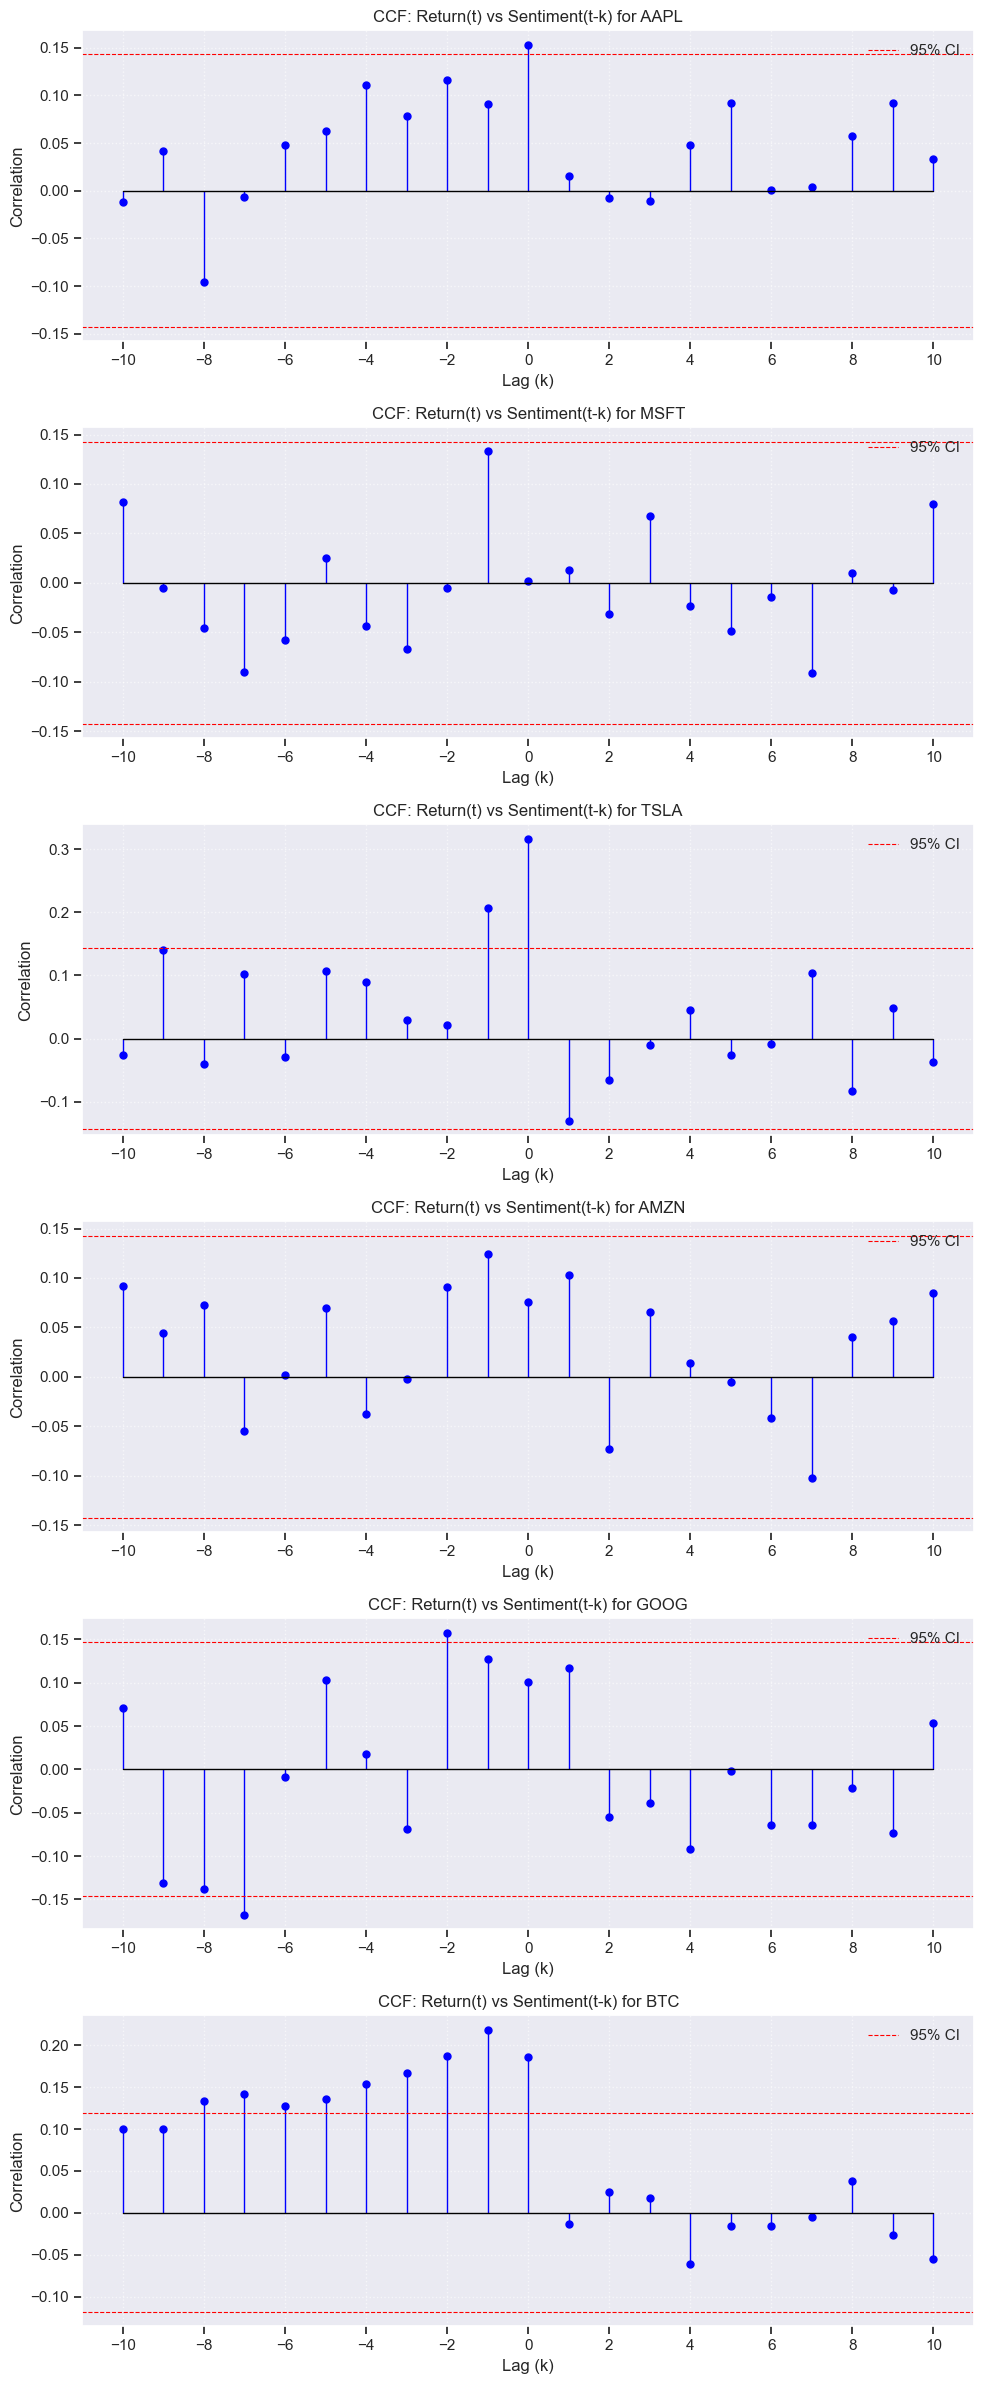

In [ ]:

print("\n--- 4) Cross-Correlation Function (CCF) ---")

ccf_results = {}
nlags = 10 

if not dfs_combined:
    print("No combined data available for CCF analysis.")
else:
    num_tickers = len(dfs_combined)

    fig, axes = plt.subplots(num_tickers, 1, figsize=(10, 4 * num_tickers), squeeze=False) 

    plot_idx = 0
    for ticker, df in dfs_combined.items():
        print(f"\nAnalyzing CCF for {ticker}:")
        ax = axes[plot_idx, 0] 

        if len(df) <= nlags:
            print(f"  Skipping {ticker}: Not enough data points ({len(df)}) for {nlags} lags.")
            ax.set_title(f'CCF: {ticker} - Insufficient Data')
            ax.text(0.5, 0.5, 'Insufficient Data', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            plot_idx += 1
            continue

        r_t = df['Return']
        S_t = df['Sentiment']

        sig_lags = plot_ccf(r_t, S_t, nlags, f'CCF: Return(t) vs Sentiment(t-k) for {ticker}', ax)
        ccf_results[ticker] = sig_lags

        print(f"  Significant Lags (k) where |Corr(Return_t, Sentiment_(t-k))| is outside 95% CI:")
        if sig_lags is not None and not sig_lags.empty:
            for i, row in sig_lags.iterrows():
                 k = int(row['Lag'])
                 corr = row['Correlation']
                 interpretation = ""
                 if k > 0: interpretation = f"Sentiment at t-{k} correlates with Return at t (Sentiment LEADS Return by {k} days)"
                 elif k < 0: interpretation = f"Sentiment at t+{-k} correlates with Return at t (Sentiment LAGS Return by {-k} days)"
                 else: interpretation = "Contemporaneous correlation (k=0)"
                 pos_neg = "Positive" if corr > 0 else "Negative"
                 print(f"    Lag {k}: {pos_neg} Correlation ({corr:.3f}) - {interpretation}")
        else:
            print("    None")

        plot_idx += 1

    plt.tight_layout()
    plt.show()


--- 5) Wavelet Coherence - Morlet ---

Processing Wavelet Coherence for AAPL...
  Running significance tests (N=188, J=78)...
NOTE: WCT significance loaded from cache.

  Significance testing complete.
  Max significant coherence within COI (R²): 0.884


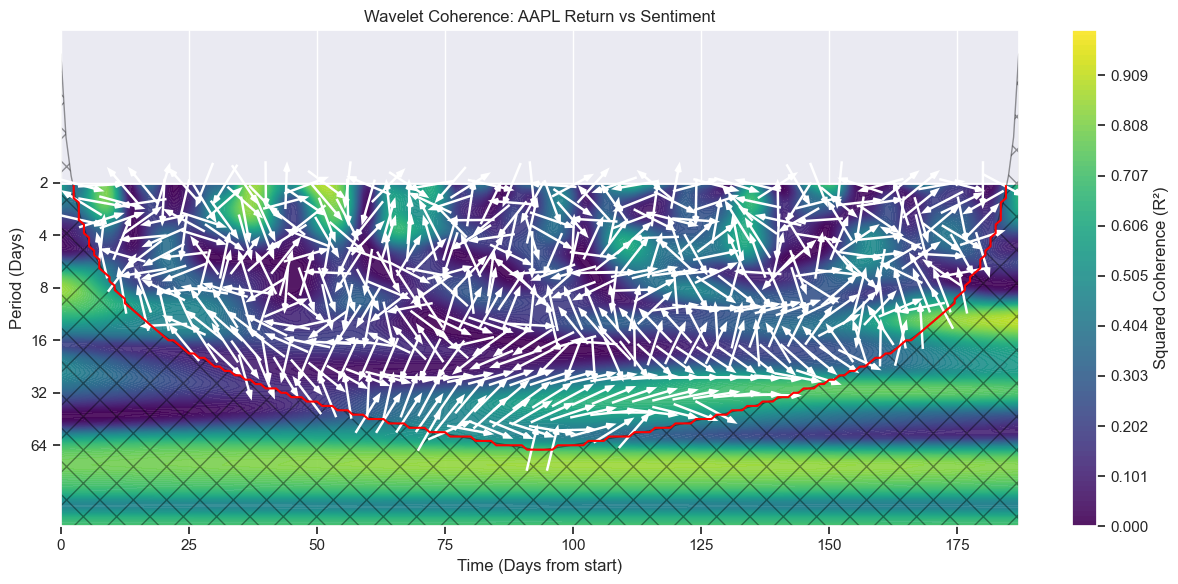

  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.

Processing Wavelet Coherence for MSFT...
  Running significance tests (N=188, J=78)...
NOTE: WCT significance loaded from cache.

  Significance testing complete.
  Max significant coherence within COI (R²): 0.915


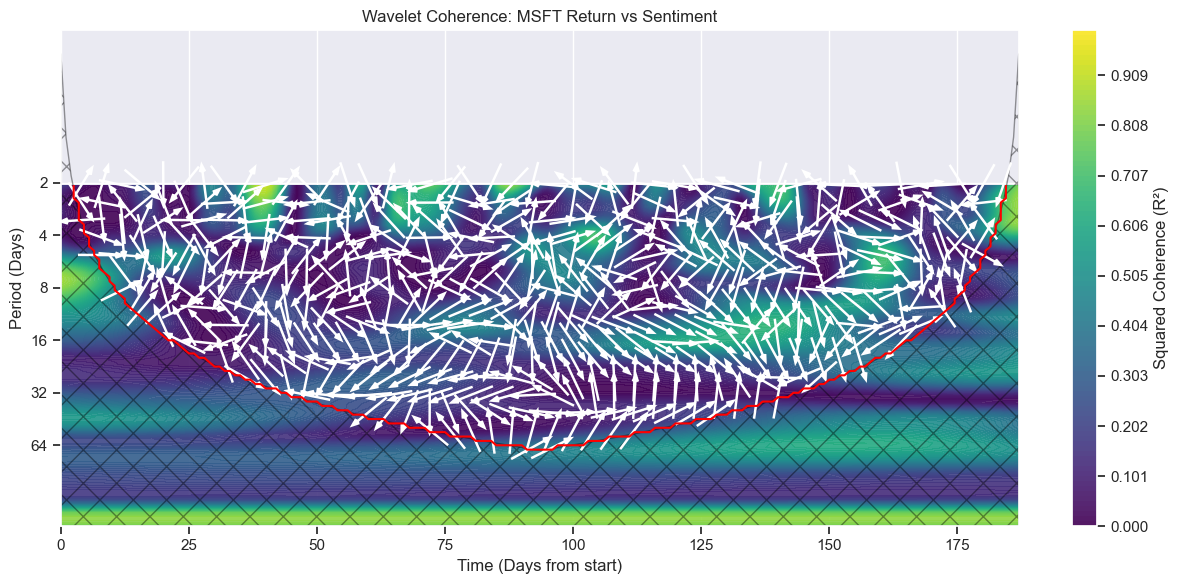

  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.

Processing Wavelet Coherence for TSLA...
  Running significance tests (N=188, J=78)...
NOTE: WCT significance loaded from cache.

  Significance testing complete.
  Max significant coherence within COI (R²): 0.933


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pycwt/wavelet.py:633: RuntimeWarning: invalid value encountered in arctanh
  aa = numpy.round(numpy.arctanh(numpy.array([al1, al2]) * 4))


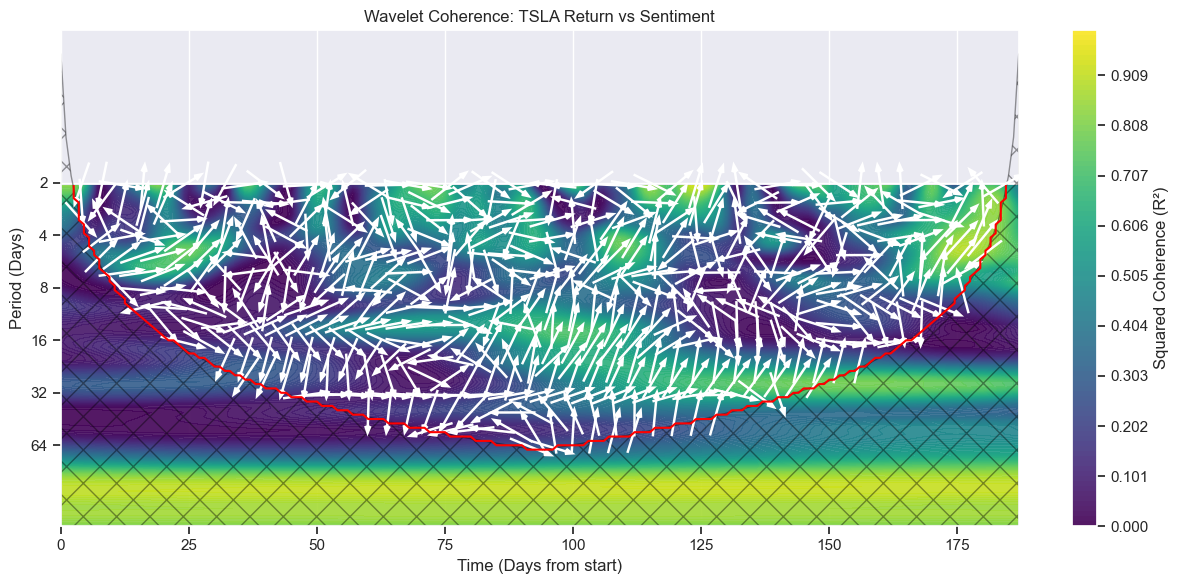

  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.

Processing Wavelet Coherence for AMZN...
  Running significance tests (N=188, J=78)...
NOTE: WCT significance loaded from cache.

  Significance testing complete.
  Max significant coherence within COI (R²): 0.878


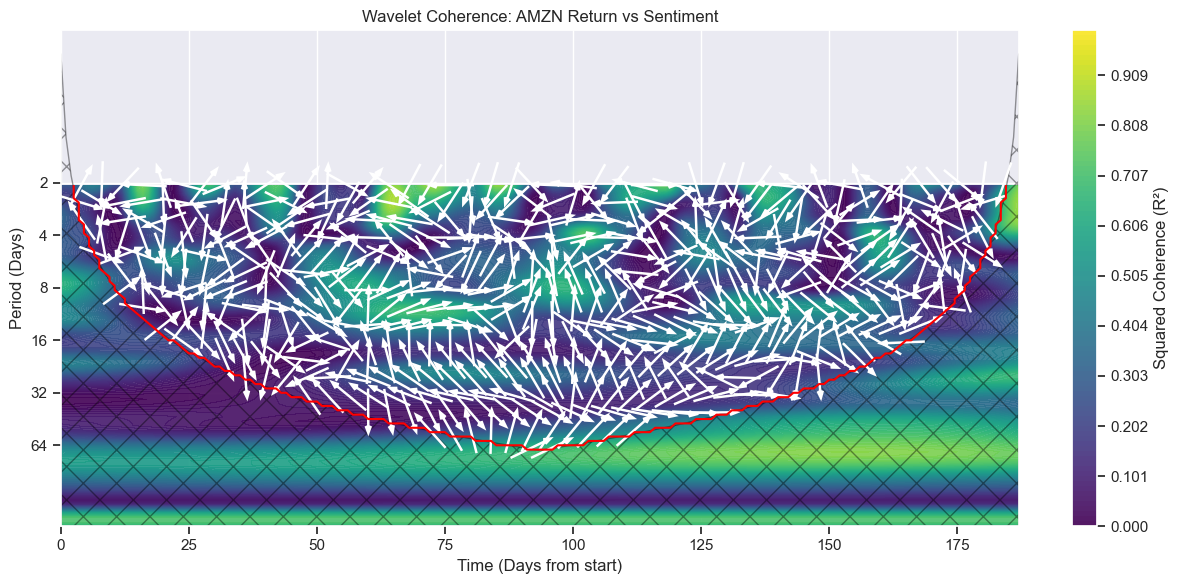

  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.

Processing Wavelet Coherence for GOOG...
  Running significance tests (N=179, J=77)...
NOTE: WCT significance loaded from cache.

  Significance testing complete.
  Max significant coherence within COI (R²): 0.890


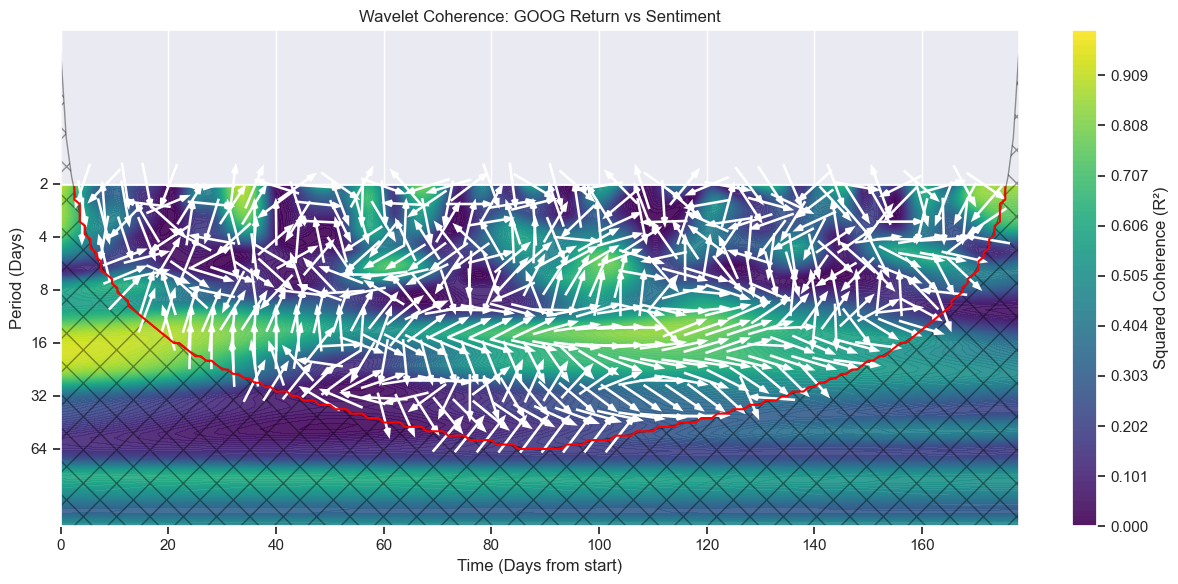

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pycwt/wavelet.py:633: RuntimeWarning: invalid value encountered in arctanh
  aa = numpy.round(numpy.arctanh(numpy.array([al1, al2]) * 4))


  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.

Processing Wavelet Coherence for BTC...
  Running significance tests (N=273, J=85)...
Calculating wavelet coherence significance


100%|██████████| 300/300 [01:34<00:00,  3.17it/s]

  Significance testing complete.
  Max significant coherence within COI (R²): 0.932


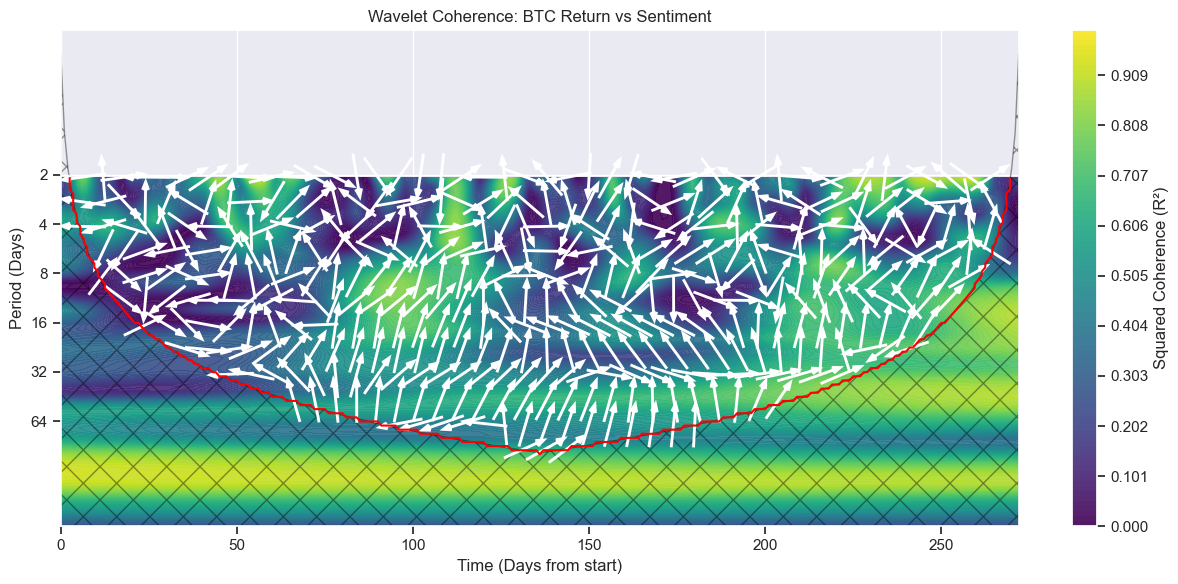

  Interpretation:
    → : In-phase (positive correlation)
    ← : Anti-phase (negative correlation)
    ↑ : Sentiment leads Returns by 90°
    ↓ : Returns lead Sentiment by 90°
  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.


In [ ]:

print("\n--- 5) Wavelet Coherence - Morlet ---")

wtc_results = {}

if 'wavelet' not in globals() or 'helpers' not in globals() or 'Morlet' not in globals() or wavelet is None or helpers is None or Morlet is None:
    print("Skipping Wavelet Coherence Analysis: PyCWT library/components not available or failed to import correctly.")
elif not dfs_combined:
    print("No combined data available for Wavelet Coherence analysis.")
else:
    dj = 1 / 12
    mother = Morlet()
    dt = 1  
    s0 = 2 * dt
    alpha = 0.05  

    for ticker in dfs_combined.keys():
        print(f"\nProcessing Wavelet Coherence for {ticker}...")

        df = dfs_combined.get(ticker)
        if df is None or df.empty:
            print(f"  Combined data for {ticker} not found or empty. Skipping.")
            wtc_results[ticker] = None
            continue

        if len(df) < 20:
            print(f"  Skipping {ticker}: Insufficient data points ({len(df)}).")
            wtc_results[ticker] = None
            continue

        dat1 = df['Return'].values
        dat2 = df['Sentiment'].values
        N = len(df)
        t = np.arange(N) * dt  

        try:
            std_dat1 = (dat1 - np.mean(dat1)) / np.std(dat1)
            std_dat2 = (dat2 - np.mean(dat2)) / np.std(dat2)
        except ZeroDivisionError:
            print(f"  Skipping {ticker}: Standard deviation is zero, cannot normalize.")
            wtc_results[ticker] = None
            continue

        J = int(np.log2(N * dt / s0) / dj)
        print(f"  Running significance tests (N={N}, J={J})...")

        try:
      
            WTC_matrix, aWTC_matrix, coi_array, freqs, sig = wavelet.wct(
                y1=std_dat1, y2=std_dat2,
                dt=dt, dj=dj, s0=s0, J=J,
                significance_level=alpha,
                wavelet=mother,
                normalize=True
            )
            print("  Significance testing complete.")

            periods = 1 / freqs
            coi_period_matrix = np.ones((len(periods), N)) * periods[:, None]
            coi_limit_matrix = np.ones((len(periods), N)) * coi_array[None, :]
            mask_coi = coi_period_matrix <= coi_limit_matrix
            mask_sig = sig[:, None] < alpha  
            valid_mask = mask_coi & mask_sig
            significant_coherence = WTC_matrix[valid_mask]
            max_coherence = np.max(significant_coherence) if significant_coherence.size > 0 else np.nan

            print(f"  Max significant coherence within COI (R²): {max_coherence:.3f}"
                  if not np.isnan(max_coherence) else "  No significant coherence found within COI.")

            wtc_results[ticker] = {
                'max_sig_coherence': max_coherence,
                'WTC': WTC_matrix,
                'aWTC': aWTC_matrix,
                'coi': coi_array,
                'freq': freqs,
                'sig': sig,
                't': t,
                'alpha': alpha,
                'periods': periods
            }

            fig, ax = plt.subplots(figsize=(12, 6))
            T, F = np.meshgrid(t, np.log2(periods))

            im = ax.contourf(T, F, WTC_matrix, levels=np.linspace(0, 1, 100), cmap='viridis', alpha=0.9)

            ax.contour(T, F, valid_mask, levels=[0.5], colors='red', linewidths=1.5)

            ax.fill_between(t, np.log2(np.max(periods)), np.log2(coi_array),
                            facecolor="none", edgecolor="black", hatch='x', alpha=0.4)

            step = max(1, N // 40)
            phase_x = T[::step, ::step]
            phase_y = F[::step, ::step]
            phase_a = aWTC_matrix[::step, ::step]
            mask_arrows = valid_mask[::step, ::step]
            angles_rad = phase_a[mask_arrows]
            U = np.cos(angles_rad)
            V = np.sin(angles_rad)

            if U.size > 0:
                ax.quiver(phase_x[mask_arrows], phase_y[mask_arrows], U, V,
                          units='width', angles='uv', scale=20, scale_units='width',
                          color='white', pivot='middle', linewidth=0.5, headwidth=3, headlength=4)

            yticks_log = np.array([2, 4, 8, 16, 32, 64])
            ax.set_yticks(np.log2(yticks_log))
            ax.set_yticklabels([f"{int(p)}" for p in yticks_log])
            ax.invert_yaxis()
            ax.set_ylabel("Period (Days)")
            ax.set_xlabel("Time (Days from start)")
            ax.set_title(f'Wavelet Coherence: {ticker} Return vs Sentiment')

            cbar = fig.colorbar(im, ax=ax, orientation='vertical', fraction=0.05, pad=0.05)
            cbar.set_label('Squared Coherence (R²)')
            plt.tight_layout()
            plt.show()

            print(f"  Interpretation:")
            print(f"    → : In-phase (positive correlation)")
            print(f"    ← : Anti-phase (negative correlation)")
            print(f"    ↑ : Sentiment leads Returns by 90°")
            print(f"    ↓ : Returns lead Sentiment by 90°")
            print(f"  Regions outside the black hatched Cone of Influence (COI) are less reliable due to edge effects.")

        except Exception as e:
            print(f"  Error calculating or plotting WTC for {ticker}: {e}")
            import traceback
            traceback.print_exc()
            wtc_results[ticker] = None


In [ ]:

print("\n--- 6) Simple Sensitivity Regression ---")

regression_results = {}

if not dfs_combined:
    print("No combined data available for regression analysis.")
else:
    for ticker, df in dfs_combined.items():
        print(f"\nAnalyzing Regression for {ticker}: r_t = a + b*S_t-1") 

        if len(df) < 3:
            print(f"  Skipping {ticker}: Not enough data points ({len(df)}) for regression.")
            regression_results[ticker] = None
            continue

        y = df['Return']
        X_lagged = df['Sentiment'].shift(1)

        data_reg = pd.concat([y, X_lagged], axis=1).dropna()
        data_reg.columns = ['Return', 'Sentiment_Lag1'] 

        if len(data_reg) < 2:
            print(f"  Skipping {ticker}: Not enough data points ({len(data_reg)}) after lagging.")
            regression_results[ticker] = None
            continue

        X_sm = sm.add_constant(data_reg['Sentiment_Lag1']) 
        y_sm = data_reg['Return']

        try:
            model = sm.OLS(y_sm, X_sm)
            results = model.fit()
            regression_results[ticker] = results 

            print(results.summary(title=f"OLS Regression: {ticker} r_t ~ S_t-1", alpha=0.05)) 

            b_coeff = results.params.get('Sentiment_Lag1', np.nan)
            b_pvalue = results.pvalues.get('Sentiment_Lag1', np.nan)
            effect_size = abs(b_coeff) if not np.isnan(b_coeff) else np.nan

            print(f"\n  Findings for {ticker}:")
            alpha_sig = 0.05
            if np.isnan(b_pvalue):
                 print(f"    Result: Could not determine significance for b (p-value is NaN).")
            elif b_pvalue < alpha_sig:
                print(f"    H0 (b=0) Test Result: Reject H0 (p={b_pvalue:.4f}). Lagged sentiment is a significant predictor of return.")
            else:
                print(f"    H0 (b=0) Test Result: Fail to reject H0 (p={b_pvalue:.4f}). Lagged sentiment is not a significant predictor of return.")
            if not np.isnan(effect_size):
                 print(f"    Effect size |b|: {effect_size:.6f}")
            else:
                 print(f"    Effect size |b|: Could not be calculated.")


        except Exception as e:
             print(f"  Error performing regression for {ticker}: {e}")
             import traceback
             traceback.print_exc()
             regression_results[ticker] = None


--- 6) Simple Sensitivity Regression ---

Analyzing Regression for AAPL: r_t = a + b*S_t-1
                       OLS Regression: AAPL r_t ~ S_t-1                       
Dep. Variable:                 Return   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.005
Method:                 Least Squares   F-statistic:                   0.04212
Date:                Sun, 11 May 2025   Prob (F-statistic):              0.838
Time:                        17:07:02   Log-Likelihood:                 461.92
No. Observations:                 187   AIC:                            -919.8
Df Residuals:                     185   BIC:                            -913.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------

In [ ]:

print("\n--- 7) Comparison: BTC vs Each Stock ---")

btc_ticker = 'BTC'

for stock_ticker in STOCK_TICKERS:
    print(f"\n>>> Comparing '{btc_ticker}' vs '{stock_ticker}':")

    has_data = btc_ticker in dfs_combined and stock_ticker in dfs_combined
    has_corr = btc_ticker in lagged_corr_results and stock_ticker in lagged_corr_results
    has_regr = btc_ticker in regression_results and regression_results[btc_ticker] is not None and \
               stock_ticker in regression_results and regression_results[stock_ticker] is not None
    has_wtc = btc_ticker in wtc_results and wtc_results[btc_ticker] is not None and \
              stock_ticker in wtc_results and wtc_results[stock_ticker] is not None

    print("\n  7.1) Correlation Comparison")
    if has_data and has_corr:
        df_btc = lagged_corr_results[btc_ticker].query("type == 'r_vs_S_lagged'").dropna()
        df_stock = lagged_corr_results[stock_ticker].query("type == 'r_vs_S_lagged'").dropna()
        if not df_btc.empty and not df_stock.empty:
            max_btc = df_btc.loc[df_btc['corr'].abs().idxmax()]
            max_stock = df_stock.loc[df_stock['corr'].abs().idxmax()]
            corr_btc, lag_btc = max_btc['corr'], int(max_btc['lag'])
            corr_stock, lag_stock = max_stock['corr'], int(max_stock['lag'])
            n_btc = len(dfs_combined[btc_ticker])
            n_stock = len(dfs_combined[stock_ticker])
            print(f"    {btc_ticker}: Max |Corr(r_t, S_t-l)| = {corr_btc:.4f} at lag {lag_btc} (N={n_btc})")
            print(f"    {stock_ticker}: Max |Corr(r_t, S_t-l)| = {corr_stock:.4f} at lag {lag_stock} (N={n_stock})")
            if n_btc > 3 and n_stock > 3:
                z1 = np.arctanh(np.clip(corr_btc, -0.999999, 0.999999))
                z2 = np.arctanh(np.clip(corr_stock, -0.999999, 0.999999))
                se_diff = np.sqrt(1 / (n_btc - 3) + 1 / (n_stock - 3))
                z_stat = (z1 - z2) / se_diff
                p_val = 2 * (1 - scipy.stats.norm.cdf(abs(z_stat)))
                print(f"    Fisher's z-test: z = {z_stat:.4f}, p = {p_val:.4f} -> {'Significant' if p_val < 0.05 else 'Not Significant'}")
            else:
                print("    Cannot perform Fisher's z-test: too few samples.")
        else:
            print("    Missing correlation data for one of the tickers.")
    else:
        print("    Missing correlation data.")

    print("\n  7.2) Regression Coefficient Comparison")
    if has_regr:
        res_btc = regression_results[btc_ticker]
        res_stock = regression_results[stock_ticker]
        b1 = res_btc.params.get('Sentiment_Lag1', np.nan)
        se1 = res_btc.bse.get('Sentiment_Lag1', np.nan)
        n1 = int(res_btc.nobs)
        b2 = res_stock.params.get('Sentiment_Lag1', np.nan)
        se2 = res_stock.bse.get('Sentiment_Lag1', np.nan)
        n2 = int(res_stock.nobs)
        if not np.isnan(b1) and not np.isnan(se1) and not np.isnan(b2) and not np.isnan(se2):
            print(f"    {btc_ticker}: b = {b1:.6f}, SE = {se1:.6f} (N={n1})")
            print(f"    {stock_ticker}: b = {b2:.6f}, SE = {se2:.6f} (N={n2})")
            pooled_se = np.sqrt(se1 ** 2 + se2 ** 2)
            if pooled_se > 0:
                t_stat = (b1 - b2) / pooled_se
                df = n1 + n2 - 4
                p_val_t = 2 * (1 - scipy.stats.t.cdf(abs(t_stat), df=df))
                print(f"    t-test: t = {t_stat:.4f}, df = {df}, p = {p_val_t:.4f} -> {'Significant' if p_val_t < 0.05 else 'Not Significant'}")
            else:
                print("    Cannot perform t-test: pooled SE is 0.")
        else:
            print("    Missing regression coefficients.")
    else:
        print("    Missing regression results.")

    print("\n  7.3) Coherence Comparison (Max R² from WTC)")
    if has_wtc:
        max_r2_btc = wtc_results[btc_ticker]['max_sig_coherence']
        max_r2_stock = wtc_results[stock_ticker]['max_sig_coherence']
        print(f"    {btc_ticker}: Max R² = {max_r2_btc:.3f}" if not np.isnan(max_r2_btc) else f"    {btc_ticker}: No significant coherence.")
        print(f"    {stock_ticker}: Max R² = {max_r2_stock:.3f}" if not np.isnan(max_r2_stock) else f"    {stock_ticker}: No significant coherence.")
        print("    (Note: Significance testing via bootstrap is omitted)")
    else:
        print("    Missing WTC results.")



--- 7) Comparison: BTC vs Each Stock ---

>>> Comparing 'BTC' vs 'AAPL':

  7.1) Correlation Comparison
    BTC: Max |Corr(r_t, S_t-l)| = 0.1858 at lag 0 (N=273)
    AAPL: Max |Corr(r_t, S_t-l)| = 0.1533 at lag 0 (N=188)
    Fisher's z-test: z = 0.3505, p = 0.7260 -> Not Significant

  7.2) Regression Coefficient Comparison
    BTC: b = -0.014142, SE = 0.062615 (N=272)
    AAPL: b = 0.002178, SE = 0.010613 (N=187)
    t-test: t = -0.2570, df = 455, p = 0.7973 -> Not Significant

  7.3) Coherence Comparison (Max R² from WTC)
    BTC: Max R² = 0.932
    AAPL: Max R² = 0.884
    (Note: Significance testing via bootstrap is omitted)

>>> Comparing 'BTC' vs 'MSFT':

  7.1) Correlation Comparison
    BTC: Max |Corr(r_t, S_t-l)| = 0.1858 at lag 0 (N=273)
    MSFT: Max |Corr(r_t, S_t-l)| = 0.0674 at lag 3 (N=188)
    Fisher's z-test: z = 1.2626, p = 0.2067 -> Not Significant

  7.2) Regression Coefficient Comparison
    BTC: b = -0.014142, SE = 0.062615 (N=272)
    MSFT: b = 0.001396, SE = 0.